# Proyek Analisis Data: Bike-sharing-dataset
- **Nama:** **Mauly Sitta Rahmania**
- **Email:** **ds009b6x0968@student.devacademy.id**
- **ID Dicoding:** **maulysitta**

## Menentukan Pertanyaan Bisnis

# **SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbedaan pola rata-rata penyewaan sepeda per jam antara pengguna terdaftar (registered) dan pengguna kasual (casual) pada hari kerja (workingday) sepanjang tahun 2012 untuk menentukan alokasi unit armada pada jam sibuk?
- **Pertanyaan 2:** Seberapa besar penurunan rata-rata penyewaan harian sepeda akibat kondisi cuaca buruk (Light Snow/Rain) dibandingkan cuaca cerah di berbagai musim selama periode 2011–2012 guna merencanakan strategi pemeliharaan armada dan promosi?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi gaya tampilan plot
sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load Dataframe day_df dan hour_df

In [3]:
# Memuat dataset day.csv dan hour.csv
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

# Menampilkan 5 baris pertama masing-masing dataframe
display(day_df.head())
display(hour_df.head())

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset `day_df` berisi data agregat harian penyewaan sepeda dengan total 731 baris dan 16 kolom.
- Dataset `hour_df` berisi data agregat per jam penyewaan sepeda dengan total 17.379 baris dan 17 kolom.

### Assessing Data

#### Identifying Data Quality Problems

In [4]:
# Memeriksa informasi tipe data dan missing values
print("=== Info day_df ===")
day_df.info()

print("\n=== Info hour_df ===")
hour_df.info()

# Memeriksa duplikasi data
print("\nJumlah duplikasi day_df:", day_df.duplicated().sum())
print("Jumlah duplikasi hour_df:", hour_df.duplicated().sum())

# Memeriksa ringkasan statistik
display(day_df.describe())

=== Info day_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

=== Info hour_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Steps to Take:**
- Mengubah tipe data pada kolom `dteday` dari `object` menjadi `datetime` pada `day_df` dan `hour_df`.
- Melakukan *mapping* nilai numerik pada kolom kategorial `season` dan `weathersit` menjadi label teks deskriptif agar lebih mudah dipahami saat analisis dan visualisasi.

**Insight:** (Opsional)
- Tidak ditemukan *missing values* maupun data duplikat pada `day_df` dan `hour_df`[cite: 1].
- Kolom `dteday` masih bertipe `object` sehingga perlu dikonversi ke format tanggal (`datetime`)[cite: 1].
- Nilai pada kolom `season` dan `weathersit` berupa kode angka (1–4) yang perlu diganti ke teks konseptual[cite: 1].

### Cleaning Data

#### Fixing data problem

In [5]:
# 1. Memperbaiki tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Membuat pemetaan label untuk kolom season dan weathersit
season_mapping = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_mapping = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Ice Pallets'
}

# Menambahkan kolom label deskriptif pada day_df
day_df['season_label'] = day_df['season'].map(season_mapping)
day_df['weather_label'] = day_df['weathersit'].map(weather_mapping)

# Menambahkan kolom label deskriptif pada hour_df
hour_df['season_label'] = hour_df['season'].map(season_mapping)
hour_df['weather_label'] = hour_df['weathersit'].map(weather_mapping)

# Memastikan hasil pembersihan data
print("=== Tipe Data Setelah Cleaning ===")
print("day_df dteday type:", day_df['dteday'].dtype)
print("hour_df dteday type:", hour_df['dteday'].dtype)

display(day_df[['dteday', 'season_label', 'weather_label']].head())

=== Tipe Data Setelah Cleaning ===
day_df dteday type: datetime64[ns]
hour_df dteday type: datetime64[ns]


,dteday,season_label,weather_label
0,2011-01-01,Spring,Misty/Cloudy
1,2011-01-02,Spring,Misty/Cloudy
2,2011-01-03,Spring,Clear/Partly Cloudy
3,2011-01-04,Spring,Clear/Partly Cloudy
4,2011-01-05,Spring,Clear/Partly Cloudy


**Insight:** (Opsional)
- Kolom `dteday` pada kedua dataframe telah berhasil dikonversi ke tipe data `datetime64[ns]`.
- Kolom kategorial baru `season_label` dan `weather_label` berhasil ditambahkan untuk meningkatkan keterbacaan data saat proses Exploratory Data Analysis (EDA) dan visualisasi.

## Exploratory Data Analysis (EDA)

### Explore Data

In [6]:
# ==========================================
# 1. EKSPLORASI DATA UMUM (OVERVIEW)
# ==========================================
print("=== 1A. Ringkasan Statistik Penyewaan Harian (day_df) ===")
display(day_df[['casual', 'registered', 'cnt']].describe())

print("\n=== 1B. Agregasi Total & Rata-Rata Penyewaan per Tahun ===")
display(day_df.groupby('yr').agg({
    'casual': ['sum', 'mean'],
    'registered': ['sum', 'mean'],
    'cnt': ['sum', 'mean', 'max', 'min']
}))

# ==========================================
# 2. EKSPLORASI PERTANYAAN 1: POLA JAM KERJA (2012)
# ==========================================
hour_2012_working = hour_df[(hour_df['yr'] == 1) & (hour_df['workingday'] == 1)]

eda_q1 = hour_2012_working.groupby('hr').agg({
    'casual': ['mean', 'max', 'min', 'sum'],
    'registered': ['mean', 'max', 'min', 'sum'],
    'cnt': ['mean', 'max', 'min', 'sum']
}).reset_index()

print("\n=== 2. Agregasi Peminjaman Sepeda per Jam pada Hari Kerja (2012) ===")
display(eda_q1)

# ==========================================
# 3. EKSPLORASI PERTANYAAN 2: PENGARUH MUSIM & CUACA
# ==========================================
eda_q2 = day_df.groupby(['season_label', 'weather_label']).agg({
    'cnt': ['count', 'mean', 'std', 'min', 'max', 'sum']
}).reset_index()

print("\n=== 3A. Agregasi Penyewaan Harian Berdasarkan Musim dan Cuaca ===")
display(eda_q2)

print("\n=== 3B. Agregasi Total & Rata-Rata Penyewaan per Musim ===")
display(day_df.groupby('season_label').agg({
    'cnt': ['count', 'mean', 'max', 'min', 'sum']
}).sort_values(by=('cnt', 'mean'), ascending=False))

=== 1A. Ringkasan Statistik Penyewaan Harian (day_df) ===


,casual,registered,cnt
count,731.000000,731.000000,731.000000
mean,848.176471,3656.172367,4504.348837
std,686.622488,1560.256377,1937.211452
min,2.000000,20.000000,22.000000
25%,315.500000,2497.000000,3152.000000
50%,713.000000,3662.000000,4548.000000
75%,1096.000000,4776.500000,5956.000000
max,3410.000000,6946.000000,8714.000000



=== 1B. Agregasi Total & Rata-Rata Penyewaan per Tahun ===


casual              registered                   cnt                     \
       sum         mean        sum         mean      sum         mean   max   
yr                                                                            
0   247252   677.402740     995851  2728.358904  1243103  3405.761644  6043   
1   372765  1018.483607    1676811  4581.450820  2049576  5599.934426  8714   

         
    min  
yr       
0   431  
1    22


=== 2. Agregasi Peminjaman Sepeda per Jam pada Hari Kerja (2012) ===


hr     casual                  registered                          cnt  \
             mean  max min    sum        mean  max min     sum        mean   
0    0   7.682731   49   0   1913   36.506024  234   3    9090   44.188755   
1    1   3.907258   23   0    969   15.451613   86   1    3832   19.358871   
2    2   2.153226   15   0    534    7.657258   68   1    1899    9.810484   
3    3   0.809129    8   0    195    4.680498   29   0    1128    5.489627   
4    4   0.636735   11   0    156    5.395918   14   0    1322    6.032653   
5    5   1.487903   10   0    369   30.512097   64   8    7567   32.000000   
6    6   4.637097   19   0   1150  122.870968  203  16   30472  127.508065   
7    7  12.689516   40   0   3147  353.858871  572  26   87757  366.548387   
8    8  24.306452   55   0   6028  580.201613  808  31  143890  604.508065   
9    9  29.229839   75   1   7249  273.161290  399  22   67744  302.391129   
10  10  39.052419  125   0   9685  130.258065  200   8   32304  169.310484   
11  11  47.564516  131   0  11796  151.161290  252   9   37488  198.725806   
12  12  52.830645  199   0  13102  200.782258  312  10   49794  253.612903   
13  13  54.859438  224   0  13660  195.526104  316  15   48686  250.385542   
14  14  58.357430  240   0  14531  171.417671  329  20   42683  229.775100   
15  15  59.108434  233   0  14718  196.883534  417  13   49024  255.991968   
16  16  61.650602  219   0  15351  309.891566  481  13   77163  371.542169   
17  17  69.775100  264   2  17374  586.413655  885  19  146017  656.188755   
18  18  60.903614  237   1  15165  556.096386  886  20  138468  617.000000   
19  19  49.337349  213   0  12285  388.425703  662  14   96718  437.763052   
20  20  37.389558  117   0   9310  274.180723  461  17   68271  311.570281   
21  21  28.028112   91   0   6979  200.923695  330   9   50030  228.951807   
22  22  22.265060   79   0   5544  146.534137  262   5   36487  168.799197   
23  23  14.943775   58   0   3721   93.899598  220   8   23381  108.843373   

                     
    max min     sum  
0   283   3   11003  
1    92   2    4801  
2    74   1    2433  
3    36   1    1323  
4    16   1    1478  
5    66   8    7936  
6   213  17   31622  
7   596  26   90904  
8   839  31  149918  
9   426  23   74993  
10  275   8   41989  
11  361  10   49284  
12  471  10   62896  
13  428  15   62346  
14  490  20   57214  
15  537  13   63742  
16  634  13   92514  
17  976  26  163391  
18  977  26  153633  
19  743  18  109003  
20  567  23   77581  
21  398  20   57009  
22  321  11   42031  
23  256   9   27102


=== 3A. Agregasi Penyewaan Harian Berdasarkan Musim dan Cuaca ===


season_label        weather_label   cnt                                  \
                                     count         mean          std   min   
0          Fall  Clear/Partly Cloudy   136  5878.257353  1356.647125  3285   
1          Fall      Light Snow/Rain     4  2751.750000  1199.339923  1842   
2          Fall         Misty/Cloudy    48  5222.479167  1431.160502  1115   
3        Spring  Clear/Partly Cloudy   111  2811.135135  1409.960622   431   
4        Spring      Light Snow/Rain     4   934.750000   826.272100   441   
5        Spring         Misty/Cloudy    66  2357.166667  1313.332082   605   
6        Summer  Clear/Partly Cloudy   113  5548.548673  1467.655078  2028   
7        Summer      Light Snow/Rain     3  1169.000000   461.679543   795   
8        Summer         Misty/Cloudy    68  4236.705882  1579.038070  1471   
9        Winter  Clear/Partly Cloudy   103  5043.563107  1595.693909  1495   
10       Winter      Light Snow/Rain    10  1961.600000  1329.287378    22   
11       Winter         Misty/Cloudy    65  4654.000000  1523.445365  1096   

                  
     max     sum  
0   8714  799443  
1   4459   11007  
2   7582  250679  
3   6312  312036  
4   2169    3739  
5   7836  155573  
6   8294  626986  
7   1685    3507  
8   8362  288096  
9   8555  519487  
10  4639   19616  
11  7852  302510


=== 3B. Agregasi Total & Rata-Rata Penyewaan per Musim ===


cnt                                  
             count         mean   max   min      sum
season_label                                        
Fall           188  5644.303191  8714  1115  1061129
Summer         184  4992.331522  8362   795   918589
Winter         178  4728.162921  8555    22   841613
Spring         181  2604.132597  7836   431   471348

**Insight:** (Opsional)
- **Dampak Musim:** Musim Fall (Gugur) dan Summer (Panas) mencatatkan rerata penyewaan harian tertinggi, melebihi 5.500 penyewaan per hari pada kondisi cuaca cerah (*Clear/Partly Cloudy*).
- **Dampak Cuaca:** Terjadi penurunan performa penyewaan yang signifikan saat cuaca buruk (*Light Snow/Rain*). Pada musim semi (*Spring*), rerata penyewaan turun hingga di bawah 1.000 sepeda per hari saat cuaca hujan/salju ringan.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

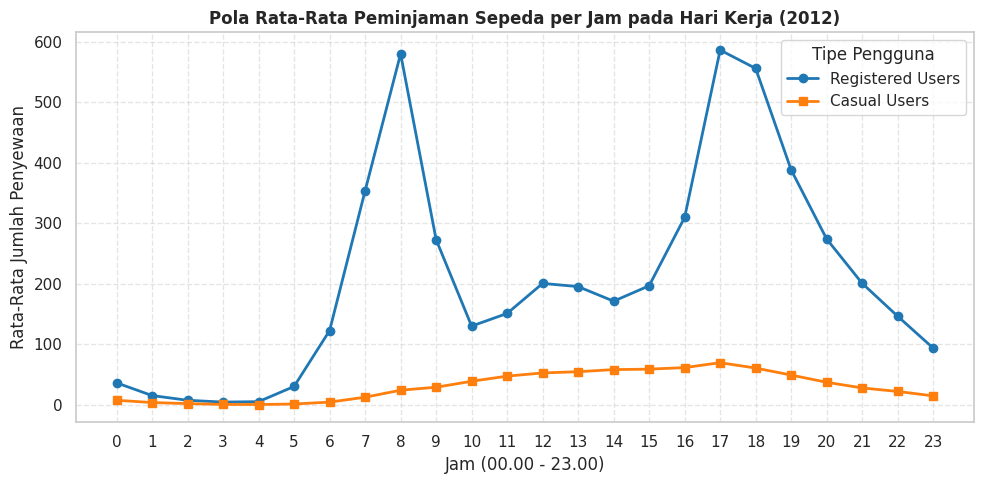

In [7]:
# Filter data hari kerja di tahun 2012
hour_2012_working = hour_df[(hour_df['yr'] == 1) & (hour_df['workingday'] == 1)]
hourly_trend = hour_2012_working.groupby('hr')[['casual', 'registered']].mean().reset_index()

# Membuat Line Chart
plt.figure(figsize=(10, 5))
plt.plot(hourly_trend['hr'], hourly_trend['registered'], label='Registered Users', marker='o', color='#1f77b4', linewidth=2)
plt.plot(hourly_trend['hr'], hourly_trend['casual'], label='Casual Users', marker='s', color='#ff7f0e', linewidth=2)

plt.title('Pola Rata-Rata Peminjaman Sepeda per Jam pada Hari Kerja (2012)', fontsize=12, fontweight='bold')
plt.xlabel('Jam (00.00 - 23.00)')
plt.ylabel('Rata-Rata Jumlah Penyewaan')
plt.xticks(range(0, 24))
plt.legend(title='Tipe Pengguna')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

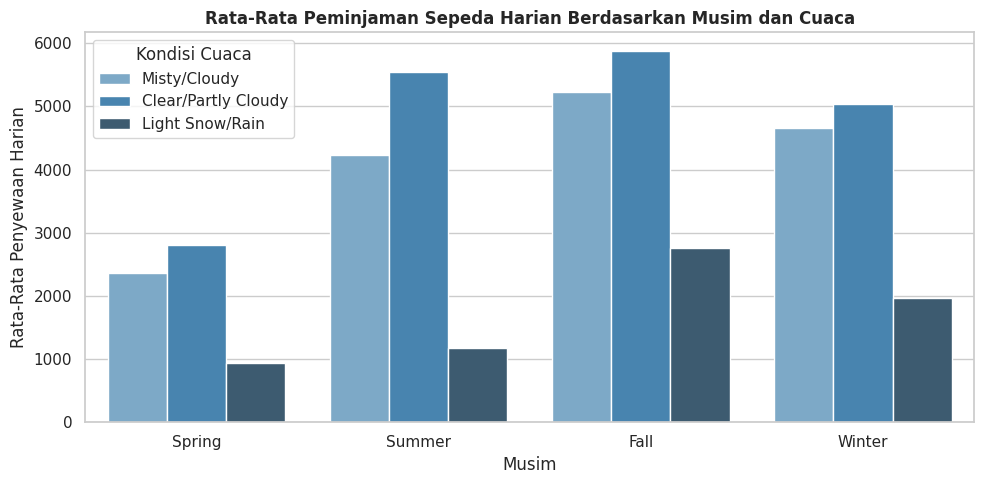

In [8]:
# Membuat Bar Chart
plt.figure(figsize=(10, 5))
sns.barplot(
    data=day_df,
    x='season_label',
    y='cnt',
    hue='weather_label',
    palette='Blues_d',
    errorbar=None
)

plt.title('Rata-Rata Peminjaman Sepeda Harian Berdasarkan Musim dan Cuaca', fontsize=12, fontweight='bold')
plt.xlabel('Musim')
plt.ylabel('Rata-Rata Penyewaan Harian')
plt.legend(title='Kondisi Cuaca')
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pola Jam Sibuk: Pengguna terdaftar (*registered*) menunjukkan lonjakan ekstrem pada jam berangkat kerja (08.00) dan jam pulang kerja (17.00 - 18.00), sedangkan pengguna kasual (*casual*) cenderung meningkat bertahap pada jam makan siang hingga sore hari.
- Sensitivitas Cuaca & Musim: Kondisi cuaca cerah (*Clear/Partly Cloudy*) pada musim *Fall* dan *Summer* menghasilkan rata-rata penyewaan harian tertinggi (mendekati 6.000 unit/hari). Sebaliknya, cuaca buruk (*Light Snow/Rain*) menurunkan volume penyewaan hingga di bawah 2.000 unit/hari di seluruh musim.

## Analisis Lanjutan (Opsional)

**Insight:** (Opsional)
- xxx
- xxx

## Conclusion & Recommendation

- **Conclusion pertanyaan 1 (Pola Peminjaman per Jam pada Hari Kerja) :** Pola peminjaman sepeda pada hari kerja menunjukkan perbedaan karakteristik yang jelas antara kedua tipe pengguna[cite: 8]. Pengguna terdaftar (*registered*) memanfaatkan sepeda sebagai moda transportasi komuter harian dengan dua titik jam sibuk (*peak hours*) yang sangat tinggi, yaitu pada pukul **08.00** (berangkat kerja/sekolah) dan pukul **17.00 - 18.00** (pulang kerja)[cite: 8]. Sementara itu, pengguna kasual (*casual*) memiliki pola peminjaman yang cenderung stabil sejak pagi dan mencapai puncaknya pada siang hingga sore hari (pukul 11.00 - 16.00)[cite: 8].
- **Conclusion pertanyaan 2 (Pengaruh Musim dan Kondisi Cuaca) :** Kondisi cuaca dan musim berpengaruh secara signifikan terhadap volume penyewaan sepeda harian[cite: 7]. Permintaan penyewaan mencapai tingkat tertinggi pada musim **Fall (Gugur)** dan **Summer (Panas)** saat cuaca **Clear/Partly Cloudy** (cerah/berawan)[cite: 7]. Sebaliknya, kondisi cuaca buruk seperti **Light Snow/Rain** (hujan/salju ringan) menyebabkan penurunan penyewaan secara drastis di seluruh musim, dengan penurunan paling tajam terjadi pada musim Spring dan Summer[cite: 7].


**Rekomendasi Action Item:**
1. **Optimasi Stok & Relokasi Armada di Jam Sibuk (*Rebalancing Strategy*):**
   Melakukan penambahan stok dan penataan ulang (*rebalancing*) unit sepeda di stasiun-stasiun area perkantoran serta pusat transportasi publik sebelum pukul 08.00 dan 17.00 pada hari kerja untuk memenuhi tingginya permintaan pengguna *registered*[cite: 8].

2. **Strategi Harga Dinamis & Promosi Khusus (*Dynamic Pricing & Promotion*):**
   Memberikan diskon tarif atau paket promosi khusus bagi pengguna kasual (*casual*) di luar jam sibuk (misalnya pukul 11.00 - 15.00) guna mengoptimalkan pemanfaatan sepeda yang menganggur (*idle units*)[cite: 8].

3. **Penjadwalan Perawatan Armada (*Maintenance Scheduling*):**
   Mengarahkan jadwal perawatan berkala (*routine maintenance*) unit sepeda pada musim dingin (*Winter*) atau hari-hari dengan prakiraan cuaca buruk/hujan, saat volume penyewaan berada pada titik terendah sehingga tidak mengganggu potensi pendapatan di musim puncak (*peak season*)[cite: 7].